In [3]:
import requests

api_url = "https://jsonplaceholder.typicode.com/todos/1"
response =  requests.get(api_url)
response.json()


{'userId': 1, 'id': 1, 'title': 'delectus aut autem', 'completed': False}

In [ ]:
api_url = "https://jsonplaceholder.typicode.com/todos"
data = {
    "userID" : 1,
    "title" : "do stuff",
    "completed" : False,
}
query = requests.post(api_url, json=data)
query.json()

{'userID': 1, 'title': 'do stuff', 'completed': False, 'id': 201}

In [ ]:
from dotenv import dotenv_values

config = dotenv_values(".env") 
weather_url = config["API_KEY_FORECAST"]
response = requests.get(weather_url)
response.json()


{'latitude': 55.44259,
 'longitude': 9.34079,
 'generationtime_ms': 0.03921985626220703,
 'utc_offset_seconds': 0,
 'timezone': 'GMT',
 'timezone_abbreviation': 'GMT',
 'elevation': 43.0,
 'hourly_units': {'time': 'iso8601', 'temperature_2m': '°C', 'rain': 'mm'},
 'hourly': {'time': ['2026-11-04T00:00',
   '2026-11-04T01:00',
   '2026-11-04T02:00',
   '2026-11-04T03:00',
   '2026-11-04T04:00',
   '2026-11-04T05:00',
   '2026-11-04T06:00',
   '2026-11-04T07:00',
   '2026-11-04T08:00',
   '2026-11-04T09:00',
   '2026-11-04T10:00',
   '2026-11-04T11:00',
   '2026-11-04T12:00',
   '2026-11-04T13:00',
   '2026-11-04T14:00',
   '2026-11-04T15:00',
   '2026-11-04T16:00',
   '2026-11-04T17:00',
   '2026-11-04T18:00',
   '2026-11-04T19:00',
   '2026-11-04T20:00',
   '2026-11-04T21:00',
   '2026-11-04T22:00',
   '2026-11-04T23:00',
   '2026-11-05T00:00',
   '2026-11-05T01:00',
   '2026-11-05T02:00',
   '2026-11-05T03:00',
   '2026-11-05T04:00',
   '2026-11-05T05:00',
   '2026-11-05T06:00',
   '2

In [27]:
forecast = response.json()["hourly"]
print(forecast.keys())
time=forecast["time"]
temp=forecast["temperature_2m"]
rain=forecast["rain"]

dict_keys(['time', 'temperature_2m', 'rain'])


<Axes: >

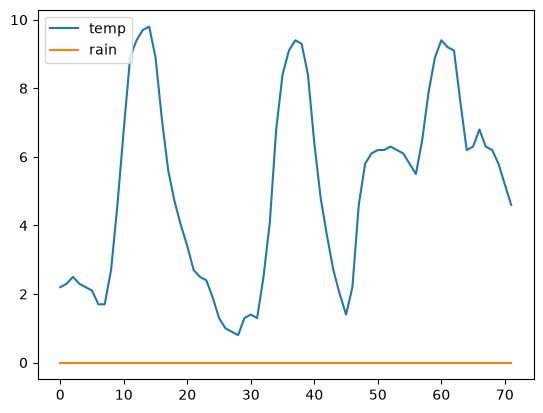

In [ ]:
import pandas as pd
df = pd.DataFrame({   
    "time": time,
    "temp": temp,
    "rain": rain
    })
df.plot()

{'type': 'FeatureCollection',
 'features': [{'type': 'Feature',
   'id': 'e17a7f42-50bf-453f-927d-0ce93fc8ace3',
   'geometry': {'type': 'Point', 'coordinates': [9.3338, 55.4376]},
   'properties': {'parameterId': 'wind_speed',
    'created': '2026-11-06T11:30:34.479715Z',
    'value': 3.7,
    'observed': '2026-11-06T11:30:00Z',
    'stationId': '06108'}},
  {'type': 'Feature',
   'id': '846dcda4-ca4b-8c53-3af1-f7fa6c9fed40',
   'geometry': {'type': 'Point', 'coordinates': [9.3338, 55.4376]},
   'properties': {'parameterId': 'humidity',
    'created': '2026-11-06T11:30:34.474549Z',
    'value': 86.1,
    'observed': '2026-11-06T11:30:00Z',
    'stationId': '06108'}},
  {'type': 'Feature',
   'id': 'b1901bc9-ac7e-f7e7-0267-9618cc489f8c',
   'geometry': {'type': 'Point', 'coordinates': [9.3338, 55.4376]},
   'properties': {'parameterId': 'pressure',
    'created': '2026-11-06T11:30:34.475436Z',
    'value': 1025.6,
    'observed': '2026-11-06T11:30:00Z',
    'stationId': '06108'}},
  {'

In [78]:
from datetime import datetime
timestamp = datetime.now().isoformat(timespec="seconds")
api_url =f"{config["API_KEY_STATION_KOLDING"]}&datetime={timestamp}%2B02:00/.."
response = requests.get(api_url)

df_data = pd.DataFrame(columns = ["temp_dry","wind_speed"])
observed =""
rows_dict={}
for datalist in response.json()["features"]:
    properties = datalist["properties"]
    if properties["observed"] != observed : 
        observed = properties["observed"]
    if properties["parameterId"] == "temp_dry" or properties["parameterId"] == "wind_speed":
        rows_dict.setdefault(properties["observed"], {})[properties["parameterId"]] = properties["value"]
df_temp = pd.DataFrame.from_dict(rows_dict,orient="index")
df_data = pd.concat([df_data,df_temp])
df_data


,temp_dry,wind_speed
2026-11-06T12:10:00Z,7.0,3.14
2026-11-06T12:00:00Z,6.9,3.65
2026-11-06T11:50:00Z,6.7,3.45
2026-11-06T11:40:00Z,6.8,3.65
2026-11-06T11:30:00Z,6.8,3.7
2026-11-06T11:20:00Z,6.8,3.6


In [83]:
response = requests.get(api_url)

for datalist in response.json()["features"]:
    print(datalist["properties"])

{'parameterId': 'temp_dew', 'created': '2026-11-06T12:10:42.730274Z', 'value': 4.1, 'observed': '2026-11-06T12:10:00Z', 'stationId': '06108'}
{'parameterId': 'temp_dry', 'created': '2026-11-06T12:10:42.730504Z', 'value': 7.0, 'observed': '2026-11-06T12:10:00Z', 'stationId': '06108'}
{'parameterId': 'wind_dir', 'created': '2026-11-06T12:10:42.730924Z', 'value': 116.0, 'observed': '2026-11-06T12:10:00Z', 'stationId': '06108'}
{'parameterId': 'wind_max', 'created': '2026-11-06T12:10:42.731282Z', 'value': 5.3, 'observed': '2026-11-06T12:10:00Z', 'stationId': '06108'}
{'parameterId': 'wind_speed', 'created': '2026-11-06T12:10:42.731637Z', 'value': 3.14, 'observed': '2026-11-06T12:10:00Z', 'stationId': '06108'}
{'parameterId': 'humidity', 'created': '2026-11-06T12:10:42.743331Z', 'value': 83.6, 'observed': '2026-11-06T12:10:00Z', 'stationId': '06108'}
{'parameterId': 'pressure', 'created': '2026-11-06T12:10:42.743831Z', 'value': 1025.4, 'observed': '2026-11-06T12:10:00Z', 'stationId': '06108

In [88]:
apiurl = "https://opendataapi.dmi.dk/v2/metObs/collections/station/items?type=Pluvio&datetime=2020-11-01T00:00:00Z/2020-12-01T00:00:00Z&status=Active&bbox=9,55,10,56"
response = requests.get(apiurl)
response.json()

{'type': 'FeatureCollection',
 'features': [{'type': 'Feature',
   'id': 'a4485bda-c594-9675-cdfe-7b6e6928d1d4',
   'geometry': {'type': 'Point', 'coordinates': [9.3768, 55.9603]},
   'properties': {'owner': 'DMI',
    'country': 'DNK',
    'anemometerHeight': None,
    'wmoCountryCode': None,
    'operationFrom': '2011-10-17T00:00:00Z',
    'parameterId': ['precip_dur_past10min',
     'precip_dur_past1h',
     'precip_past10min',
     'precip_past1h',
     'precip_past1min'],
    'created': '2026-10-14T10:51:09Z',
    'barometerHeight': None,
    'validFrom': '2011-10-17T00:00:00Z',
    'type': 'Pluvio',
    'stationHeight': 91.0,
    'regionId': '6',
    'name': 'Nørre Snede',
    'wmoStationId': None,
    'operationTo': None,
    'updated': None,
    'stationId': '05202',
    'validTo': None,
    'status': 'Active'}},
  {'type': 'Feature',
   'id': 'c0bfa605-3dcf-13c5-32b7-d3960d6a4b7c',
   'geometry': {'type': 'Point', 'coordinates': [9.7022, 55.961]},
   'properties': {'owner': 'D

In [90]:
import folium

stations = response.json()["features"]

# Keep only rain gauges
pluvio_stations = [s for s in stations if s["properties"]["type"] == "Pluvio"]

# Center the map on the first station (GeoJSON order is [longitude, latitude])
first_lon, first_lat = pluvio_stations[0]["geometry"]["coordinates"]
rain_map = folium.Map(location=[first_lat, first_lon], zoom_start=7, tiles="CartoDB positron")

for station in pluvio_stations:
    lon, lat = station["geometry"]["coordinates"]
    folium.Marker(
        location=[lat, lon],  # folium expects [latitude, longitude]
        tooltip=f"{station['properties']['name']} ({station['properties']['stationId']})",
    ).add_to(rain_map)

rain_map.save("rain_gauges_map.html")

c:\Users\Florian\Documents\python\API training\.venv\Lib\site-packages\folium\raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore
